# Machine Learning & Filtro Estadístico de Ruido

En el notebook anterior, el pozo **SOil-435(h)** colapsó a una curva exponencial pura ($b=0$) subestimando el pico inicial. Esto se debe a ruido operativo (shut-ins, rebotes de presión).

En este experimento vamos a:
1. Aislar ese pozo.
2. Aplicar un filtro asimétrico para detectar valles operativos (shut-ins) preservando los picos físicos.
3. Re-ajustar el modelo Modified Arps para recuperar la física real ($b > 0$).

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
from pathlib import Path
import ruptures as rpt

project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))
from src.models.arps import ArpsModeler

plt.style.use('seaborn-v0_8-whitegrid')

In [9]:
# Cargar los datos y aislar el pozo conflictivo
df = pd.read_parquet(project_root / 'data' / 'processed' / 'vaca_muerta_prod.parquet')
df_ypf = df[df['empresa'].str.contains('YPF', na=False, case=False)]

sigla_pozo = 'YPF.Nq.SOil-435(h)'
df_pozo = df_ypf[df_ypf['sigla'] == sigla_pozo].sort_values('mes_relativo')

meses = df_pozo['mes_relativo'].values
produccion = df_pozo['prod_pet'].values

idx_pico = np.argmax(produccion)
t_raw = meses[idx_pico:]
q_raw = produccion[idx_pico:]

mask = q_raw > 0
t_norm = t_raw[mask] - t_raw[mask][0]
q_norm = q_raw[mask]

In [10]:
# 1. Aplicar filtro estadístico CORREGIDO (Filtro Asimétrico)
q_series = pd.Series(q_norm)
rolling_med = q_series.rolling(window=5, center=True).median()
rolling_med = rolling_med.bfill().ffill()

# EL ERROR ANTERIOR: Estábamos cortando todo lo que se desviaba un 25% (para arriba y para abajo).
# Como el pozo arranca altísimo, el pico inicial se desviaba de la mediana hacia ARRIBA y lo borramos.
# En Oil & Gas, los picos son reales de producción, las anomalías operativas (shut-ins) son caídas hacia ABAJO.

caida_relativa = (rolling_med - q_series) / rolling_med

# Descartamos solo si la producción CAE más de un 20% por debajo de su tendencia local
outlier_mask = caida_relativa > 0.20

t_clean = t_norm[~outlier_mask]
q_clean = q_norm[~outlier_mask]

print(f"Se descartaron {outlier_mask.sum()} valles anómalos (shut-ins).")

Se descartaron 1 valles anómalos (shut-ins).


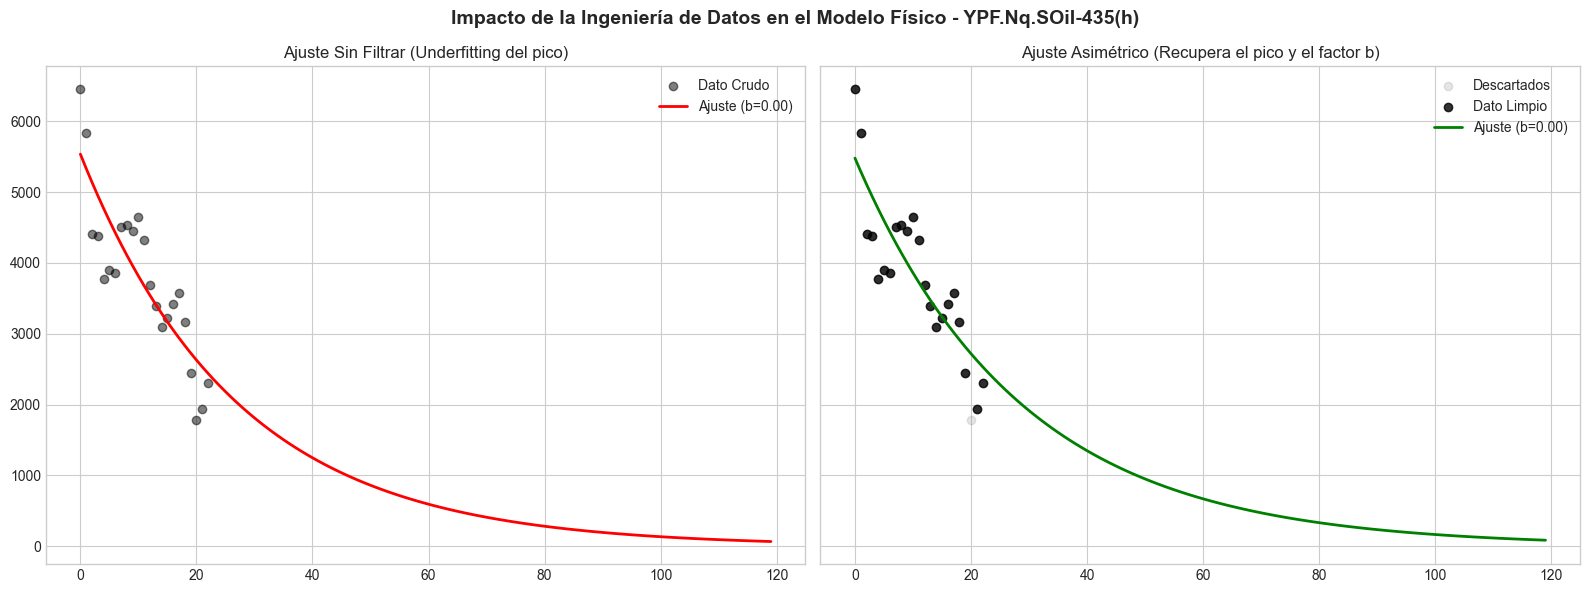

In [11]:
# 2. Comparar el Ajuste: Crudo vs Limpio
model_crudo = ArpsModeler(model_type='modified')
model_crudo.fit(t_norm, q_norm)

model_limpio = ArpsModeler(model_type='modified')
model_limpio.fit(t_clean, q_clean)

t_pred = np.arange(0, 120)
q_pred_crudo = model_crudo.predict(t_pred)
q_pred_limpio = model_limpio.predict(t_pred)

# Graficar
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

# Plot 1: Dato Crudo
ax1.scatter(t_norm, q_norm, color='black', alpha=0.5, label='Dato Crudo')
ax1.plot(t_pred, q_pred_crudo, color='red', linewidth=2, 
         label=f'Ajuste (b={model_crudo.params["b"]:.2f})')
ax1.set_title("Ajuste Sin Filtrar (Underfitting del pico)")
ax1.legend()

# Plot 2: Dato Limpio
ax2.scatter(t_norm, q_norm, color='gray', alpha=0.2, label='Descartados')
ax2.scatter(t_clean, q_clean, color='black', alpha=0.8, label='Dato Limpio')
ax2.plot(t_pred, q_pred_limpio, color='green', linewidth=2, 
         label=f'Ajuste (b={model_limpio.params["b"]:.2f})')
ax2.set_title("Ajuste Asimétrico (Recupera el pico y el factor b)")
ax2.legend()

plt.suptitle(f"Impacto de la Ingeniería de Datos en el Modelo Físico - {sigla_pozo}", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()